# 08 — The two L2 partitions of the H100 NVL: near and far hits for every SM, line homes, copies and the address hash

**Goal.** The 60 MiB L2 cache of this GPU is split into two partitions, each attached to half of the SMs. An L2 hit therefore costs one of two latencies depending on where the line is held relative to the requesting SM. This experiment answers the questions a placement-aware model of the chip needs:

1. For **every one of the 132 SMs**: which partition is near, what a near hit and a far hit cost, and whether there is finer structure inside a partition (sub-nodes).
2. **Where a line lives.** Is its home decided by the SM that touches it first, or by its address? If by its address, which address bits decide?
3. **Copies.** Does a read from the far side leave a copy in the reader's partition, who can use that copy, and what happens to it when the line is written?
4. **Effective capacity.** How much data can one SM keep in L2 before its accesses turn into far hits and misses?

## Background

**L2 partitions.**
- The L2 is built from 96 slices (the profiler reports 96 `lts` units) grouped into two partitions.
- Each GPC (group of 12–18 SMs) is wired to one partition. An SM reaches the other partition only through a link between the two.
- A line held only in the other partition is therefore a *far hit*: the request and the data cross that link.

**Home and copies.** Two policies are possible:
- *first-touch homing*: a line lives in the partition of the SM that first touched it;
- *address homing*: an address function chooses the partition, as it chooses the slice.

Independently, the partition of a reader may keep a **copy** of a far line, so that later reads are near. A copy raises two questions:
- does it serve only the SM that created it, or every SM of that partition?
- is it invalidated when the line is written?

**Why only the first read can be far.** If reads leave copies, a pointer chase that revisits its lines sees far hits only on the very first visit of each line by a partition. Measuring far hits therefore requires full control of the cache state:
1. remove the line from the L2;
2. let a chosen SM touch it;
3. time the first read from the probe SM.

**Address bits.**
- Memory is allocated in 2 MiB pages, so bits 0–20 of an address are the same in the virtual and the physical address. Higher bits are chosen by the driver's page mapping.
- A hash that selects one of two partitions is typically the parity (XOR) of a set of address bits. Flipping one bit of the set changes the partition; flipping a bit outside it never does; flipping two bits of the set changes nothing.
- If the hash is linear in this sense, single-bit flips predict every multi-bit flip.

**Per-access timing.** One thread reads `%clock64`, issues a load, and reads `%clock64` again once the loaded value is available. The second read is made to depend on the loaded value:
```
t0 = %clock64;  p = ld.global.cg.u64 [p];  t1 = %clock64 (issued after p arrived)
```
The difference includes the cost of the timer pair itself, which is measured separately and subtracted. Each line stores its own address in its first 8 bytes, so `p = *p` re-reads the same line with every load depending on the previous one.

## Experimental setup

**Device and configuration.**
- NVIDIA H100 NVL: 132 SMs in 8 GPCs, 60 MiB L2, HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off.
- Driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`).
- SM clock locked at 1635 MHz with `nvidia-smi -lgc`. Each configuration is followed by an NVML sample of clocks and throttle reasons (table below).
- GPC numbering G0–G7 and the SM → GPC map come from an earlier cluster-placement experiment on the same card.

**Common protocol (every configuration).**
1. **Empty the L2.** Read-modify-write a 128 MB buffer, then read another 128 MB buffer, so that no line of the test buffer is cached and no dirty line is being written back during the measurement.
2. **Touch.** A single warp pinned to a chosen SM writes each test line completely: 128 bytes, the first 8 being the line's own address. This is the line's first touch.
3. **Probe.** One block per SM is launched with 200 KB of shared memory each, so every SM holds exactly one block; only the block on the probe SM works. One thread visits the lines one after another. For each line it:
   - first reads, untimed, a reserved line of the same 2 MiB page, so that the first timed read does not pay an address-translation miss;
   - then times 64 dependent reads of the line (sample 0 = the probe SM's first read of the line).

   Samples are kept in shared memory and copied out between lines, outside the timed pairs.

Pinning works by `%smid`: each block reads its SM id and only the one on the target SM proceeds; the host checks and re-launches if needed.

**Naming.** The partition containing SM 0 (GPC 0) is called partition 0, the one containing SM 2 (GPC 1) partition 1. A *labelling pass* gives each test line its home:
1. SM 0 writes the candidate lines;
2. SM 2 reads each line once;
3. a far first read means the line is homed in partition 0, a near one in partition 1.

**Kernels.**
- **K1, one line, 64 reads.**
  - Probes SM 0 and SM 2; 32 lines (16 homed in each partition).
  - Toucher: the probe itself, or the SM of the other partition.
  - With or without one untimed warm-up read; `ld.global.cg` (L2 only) and `ld.global.ca` (L1 allowed).
  - 5 launches per configuration.
- **K5, every SM.**
  - 256 lines of an 8 MiB buffer: 128 homed in each partition, each written by an SM of its home partition, so every line exists only at home.
  - For each of the 132 SMs and 5 repetitions: empty the L2, touch, then the SM reads every line 64 times.
  - The first read gives near and far latencies per SM; reads 2–64 give the latency of whatever copy the first read left.
- **K2, address bits.**
  - A 2 GiB buffer. Line sets:
    - 32 random base lines L and, for every bit b from 7 to 30, the line L ⊕ 2^b;
    - every pair of bits 7–20 flipped together, plus 32 random multi-bit masks of bits 7–20 per base;
    - 4 fixed in-page offsets in all 1024 pages.
  - All lines are written by one reference SM and first-read by the reference SM of the other partition, in a random order, in both directions, 3 repetitions. A line's home is the class (near or far) of its first read.
- **K3, copies.**
  - Three SMs: A; B in the other partition; C in B's partition but another GPC. Three such triples plus one control triple with all three SMs in one partition.
  - 32 lines (16 homed with A, 16 with B).
  - Sequence:
    1. empty the L2, A writes the lines;
    2. B reads (64 times each);
    3. C reads;
    4. A reads;
    5. A rewrites the lines with a new value;
    6. B reads again, and checks that it sees the new value.
  - Each step is either its own kernel launch, or all steps run in one launch ordered by release/acquire flags in global memory. 5 repetitions.
- **K4, effective capacity.**
  - A random cyclic pointer chain over one 128-byte line after another, footprints 16–80 MiB in 2 MiB steps.
  - Touched by the probe SM itself, or alternately by SM 0 and SM 2 (even/odd lines).
  - The probe (SM 0 or SM 2) then chases the whole chain three times, timing every hop into an on-chip histogram (exact counts per cycle value), and a fourth time untimed. 3 repetitions.
- **Hardware counters.** Nsight Compute in application-replay mode (every counter pass re-runs the whole protocol), with the clock lock kept:
  - one line × 64 reads per profiled kernel;
  - 65 k far or near first reads;
  - the K4 chase after two warm passes.

In [1]:
%matplotlib inline
import os
import re
import sys
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from common08 import runs, latest_run, read_run, kmeans1d, timer_pair
from analysis08 import gpc_map, load_k5, sm_signature, line_groups, k2_bits, k2_linearity, quad_table

QUICK = os.environ.get("NB08_QUICK") == "1"
R, EXP = "results", "08__l2_partitions_and_first_touch"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#a35bd0", "#d4a20c", "#d6457a", "#4fb3c8", "#7a6e5c"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 1)

reg = runs()
RID = {m: latest_run(t, m, QUICK) for t, m in [("l2_probe", "calib"), ("l2_probe", "k1"), ("l2_probe", "k2"), ("l2_probe", "k3"),
                                              ("l2_probe", "k5"), ("l2_capacity", "k4")]}
GPC = gpc_map()
TP = timer_pair(quick=QUICK)
def last_tag(f):
    d = pd.read_csv(f"{R}/{f}")
    return d[d.run_id == d.run_id.max()]
NCU = {t: last_tag(f"08__l2__ncu_{t}.csv") for t in ("lines", "fabric", "capacity")}
# Under application replay the binary runs once per counter pass; the first pass ran the profiled kernels 2.5–4× slower
# (see section 6), so their cycle counts are taken as the median over the other passes' manifests.
_man = pd.read_csv(f"{R}/08__l2__ncu_manifest.csv")
for t, mode in [("lines", "ncu_lines"), ("fabric", "ncu_fabric"), ("capacity", "ncu_capacity")]:
    r0, nb = NCU[t].run_id.iloc[0], int(NCU[t].binary_runs.iloc[0])
    rs = sorted(_man[(_man["mode"] == mode) & (_man.run_id >= r0)].run_id.unique())[:nb]
    mm = _man[_man.run_id.isin(rs)]
    NCU[t]["first_median_pass1"] = NCU[t].first_median
    NCU[t]["first_median"] = NCU[t].ncu_order.map(mm[mm.run_id != rs[0]].groupby("ncu_order").first_median.median())
    NCU[t]["pass_runs"] = len(rs)
MHZ = float(NCU["capacity"]["sm__cycles_elapsed.avg.per_second"].median() / 1e6)
clog = pd.read_csv(f"{R}/{EXP}__clock_log.csv")
stats = pd.read_csv(f"{R}/08__l2__launch_stats.csv")
print("runs used:", RID)

runs used: {'calib': '2026-10-24T21:42:05.209+00:00', 'k1': '2026-10-24T21:42:05.870+00:00', 'k2': '2026-10-24T21:42:07.555+00:00', 'k3': '2026-10-24T21:42:11.775+00:00', 'k5': '2026-10-24T21:42:13.213+00:00', 'k4': '2026-10-24T21:42:20.004+00:00'}


In [2]:
L = clog[(clog.phase == "launch") & clog.run_id.isin(RID.values())]
first = L.iloc[0]
display(pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all configurations)": [f"{L.sm_clock_mhz.min()}–{L.sm_clock_mhz.max()} MHz"],
    "SM clock measured by the profiler (median)": [f"{MHZ:.0f} MHz"],
    "memory clock (NVML)": [f"{L.mem_clock_mhz.min()}–{L.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{L.power_w.min():.0f}–{L.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{L.gpu_temp_c.max()} / {L.mem_temp_c.max()} °C"],
}).T.rename(columns={0: ""}))
used = reg[reg.run_id.isin(RID.values())].assign(mode=lambda r: r.cmdline.str.split().str[:2].str.join(" "))
st = stats[stats.run_id.isin(RID.values())].groupby("run_id")[["configs", "claim_retries", "bad_clock_configs"]].sum()
used = used.join(st, on="run_id")
display(used[["run_id", "mode", "complete", "configs", "claim_retries", "bad_clock_configs"]]
        .rename(columns={"configs": "recorded configurations", "claim_retries": "re-launches (no block on the target SM / flag timeout)",
                         "bad_clock_configs": "configurations with a clock warning"}).reset_index(drop=True))
cal = read_run("08__l2__probe.csv", RID["calib"])
print(f"timer calibration: per-access-timed ld.shared median {cal.cycles.median():.0f} cycles (p5–p95 {cal.cycles.quantile(.05):.0f}–"
      f"{cal.cycles.quantile(.95):.0f}) over {len(cal)} samples on SMs {sorted(cal.probe_smid.unique())}; "
      f"ld.shared latency 23 cycles → timer pair {TP:.0f} cycles, subtracted from every latency below")
sass = open("results/sass/l2_probe.sass").read().split("Function : ")
blk = [b for b in sass if b.startswith("_Z7k_probeILi0EE")][0].splitlines()
ins = [l.split(";")[0].split("*/")[-1].strip() for l in blk if re.search(r"/\*[0-9a-f]{4}\*/", l)]
i = max(j for j, l in enumerate(ins) if l.startswith("CS2R") and "CLOCK" in l and ins[j + 1].startswith("LDG"))
print("\nSASS of the timed sample (k_probe, ld.global.cg):\n  " + "\n  ".join(ins[i:i + 4]))

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all configurations),1635–1635 MHz
SM clock measured by the profiler (median),1631 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),87–92 W
GPU / HBM temperature max,32 / 36 °C


,run_id,mode,complete,recorded configurations,re-launches (no block on the target SM / flag timeout),configurations with a clock warning
0,2026-10-24T21:42:05.209+00:00,bin/l2_probe calib,True,6,0,0
1,2026-10-24T21:42:05.870+00:00,bin/l2_probe k1,True,81,0,0
2,2026-10-24T21:42:07.555+00:00,bin/l2_probe k2,True,6,0,0
3,2026-10-24T21:42:11.775+00:00,bin/l2_probe k3,True,41,0,0
4,2026-10-24T21:42:13.213+00:00,bin/l2_probe k5,True,661,0,0
5,2026-10-24T21:42:20.004+00:00,bin/l2_capacity k4,True,396,0,0


timer calibration: per-access-timed ld.shared median 26 cycles (p5–p95 26–26) over 24576 samples on SMs [np.int64(0), np.int64(2)]; ld.shared latency 23 cycles → timer pair 3 cycles, subtracted from every latency below

SASS of the timed sample (k_probe, ld.global.cg):
  CS2R R8, SR_CLOCKLO
  LDG.E.64.STRONG.GPU R4, desc[UR6][R4.64]
  LOP3.LUT R13, R4, UR8, RZ, 0xc0, !PT
  CS2R R10, SR_CLOCKLO


## Results

### 1. One line, 64 reads (K1)

**Figure 1 — one line read 64 times in a row.** For each line the probe SM's 64 dependent reads are timed individually: median over the 16 lines of each kind and 5 launches, p5–p95 shaded. Two variables:
- who wrote the line after the L2 was emptied: the probe itself, or the reference SM of the other partition;
- where the line's home is relative to the probe ("home near" / "home far", from the labelling pass).

Left: `ld.global.cg`. Right: `ld.global.ca`, which may cache the line in the SM's L1.

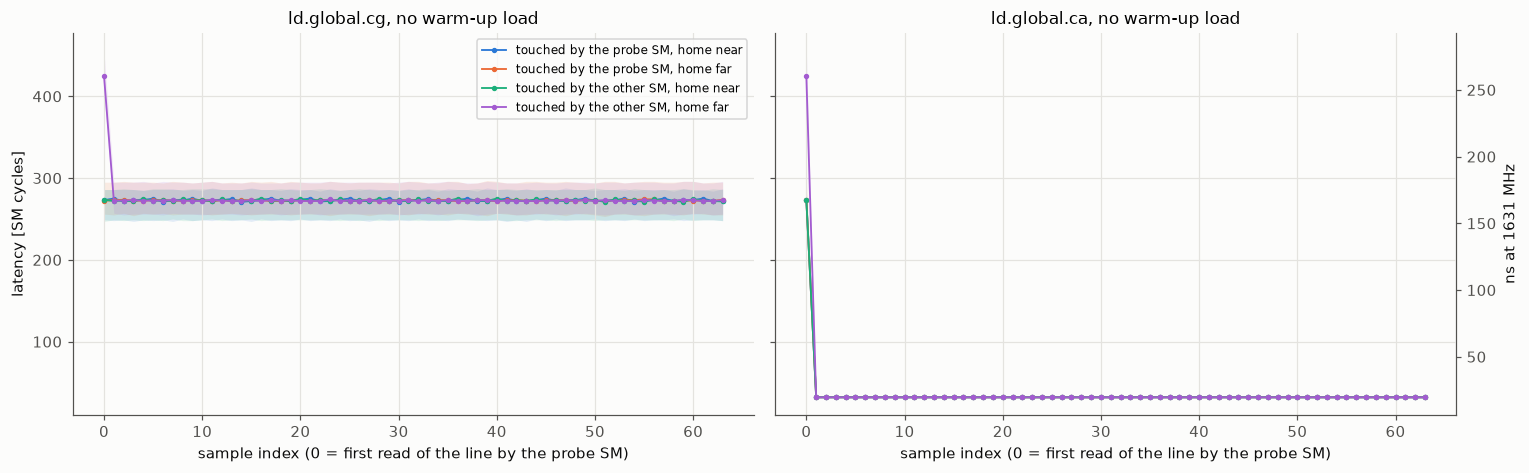

In [3]:
k1 = read_run("08__l2__probe.csv", RID["k1"])
k1 = k1[k1.kernel == "K1"].copy()
k1["cyc"] = k1.cycles - TP
part_of = {0: 0, 2: 1}  # partitions are named after SM 0 (label 0) and SM 2 (label 1)
k1["home"] = np.where(k1.line_home == k1.probe_smid.map(part_of), "home near", "home far")
k1["touch"] = np.where(k1.first_touch_smid == k1.probe_smid, "touched by the probe SM", "touched by the other SM")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, v in zip(axs, ["cg", "ca"]):
    for c, (t, h) in zip(PAL, [(t, h) for t in ["touched by the probe SM", "touched by the other SM"] for h in ["home near", "home far"]]):
        d = k1[(k1.load_variant == v) & (k1.warm == 0) & (k1.touch == t) & (k1.home == h)]
        g = d.groupby("sample_idx").cyc
        ax.plot(g.median().index, g.median(), "-o", ms=2.5, lw=1.2, color=c, label=f"{t}, {h}")
        ax.fill_between(g.median().index, g.quantile(.05), g.quantile(.95), color=c, alpha=0.12, lw=0)
    ax.set_title(f"ld.global.{v}, no warm-up load"); ax.set_xlabel("sample index (0 = first read of the line by the probe SM)")
axs[0].set_ylabel("latency [SM cycles]"); axs[0].legend(fontsize=8)
sec = axs[1].secondary_yaxis("right", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_ylabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()
k1["sample"] = np.where(k1.sample_idx == 0, "sample 0", "samples 1–63")
t = k1.groupby(["load_variant", "warm", "touch", "home", "sample"]).cyc.median().unstack("sample")
display(t.round(0).style.format("{:.0f}").set_caption("median cycles (timer pair removed); probes SM 0 and SM 2, 32 lines, all launches"))

- **Only one case is ever far:** a line homed in the other partition *and* written by an SM of that other partition. Then the probe's first read costs ≈ 425 cycles and every later read ≈ 273.
- **Writing a line also leaves a copy.** When the probe itself wrote a far-homed line, its first read is already near (272): the write left a copy in the writer's partition.
- **One untimed warm-up read gives the same result:** every timed read is then near. A single read therefore suffices to create the copy.
- **`.ca` against `.cg`.** With `.ca`, reads 2–64 cost 32 cycles: they are L1 hits, and the profiler counts 63 L1 hits per line (section 6). With `.cg` they stay at ≈ 273 with no L1 hit, so every `.cg` number in this notebook is an L2 latency.

### 2. Every SM (K5)

Every SM read 256 lines, each held only in its home partition: 128 homed in partition 0, 128 in partition 1. The first read of each line is near or far depending on the reading SM's partition; reads 2–64 hit whatever copy the first read left. All per-SM values are medians over 5 repetitions.

**Figure 2 — every SM.**
- Rows are GPCs, ordered by partition and sub-node (labels derived below); cells are SMs, labelled with their SM id.
- (a), (b): first reads of lines homed in the SM's own partition, split by the sub-node group of the line.
- (d), (e): the same for lines homed in the other partition.
- (c), (f): the differences.

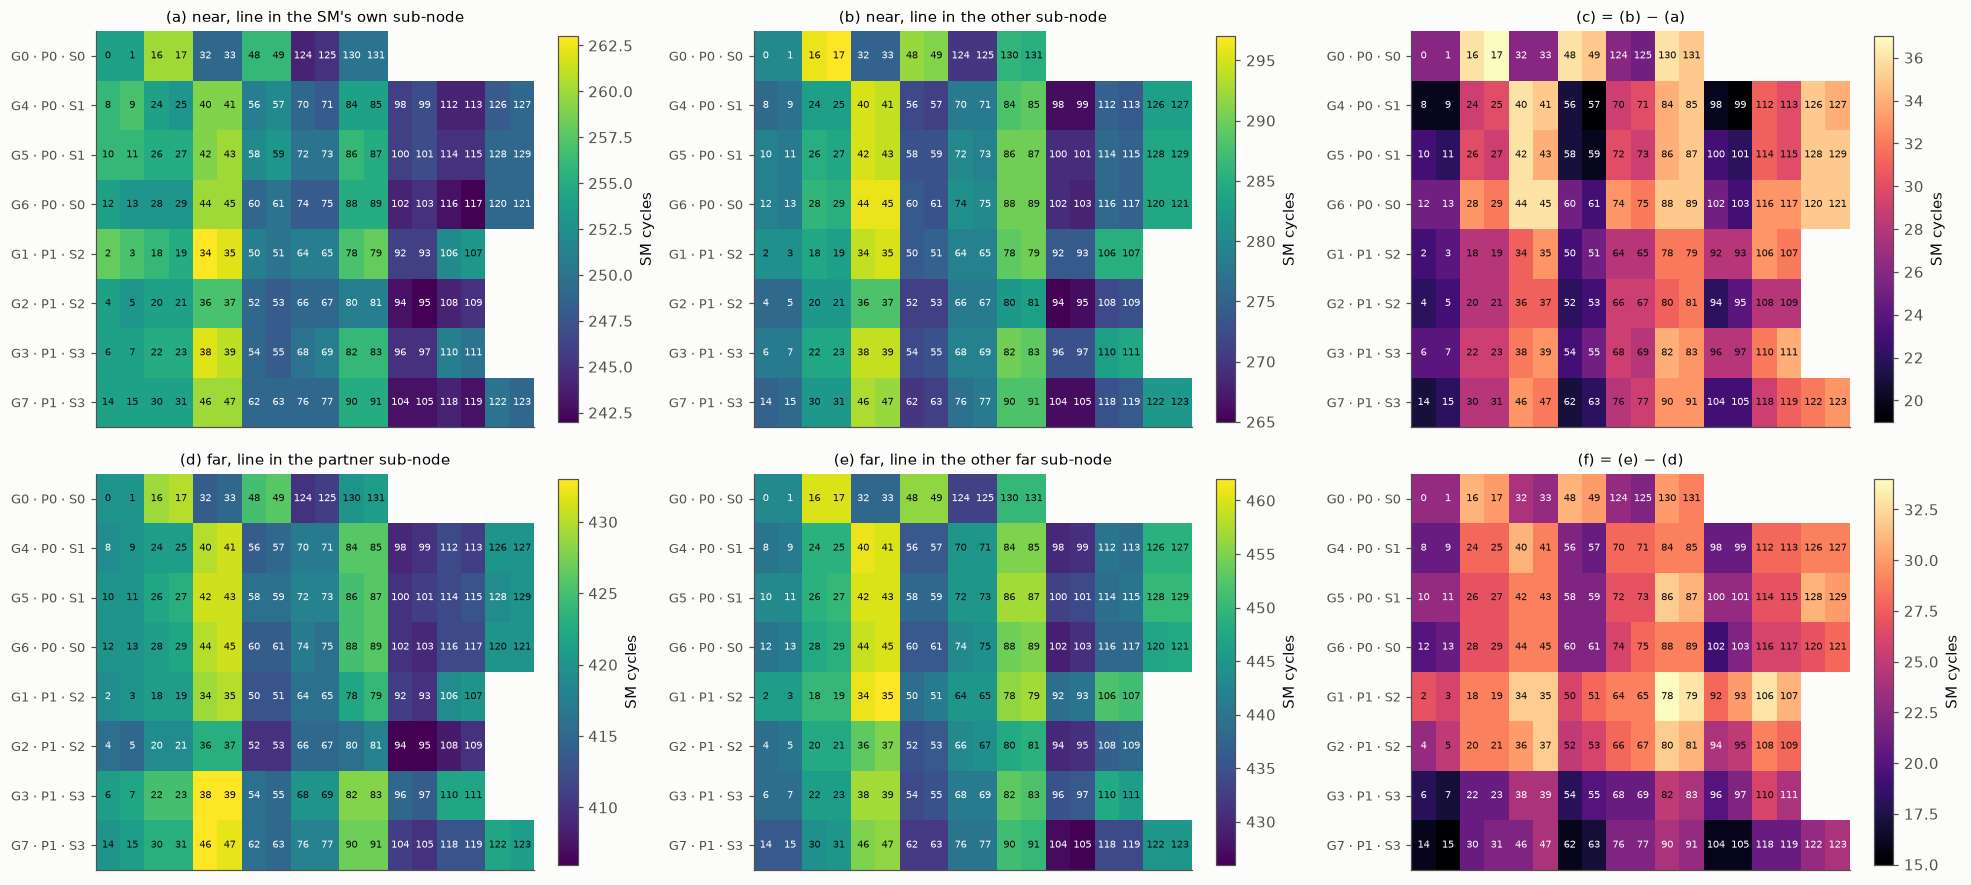

In [4]:
k5, seq = load_k5(RID["k5"], samples=True)
sig, groups = sm_signature(k5, TP)
order = sig.sort_values(["partition", "gpc", "smid"])
gpcs = [g for p in (0, 1) for g in sorted(order[order.partition == p].gpc.unique())]
W = int(sig.groupby("gpc").size().max())
sig["far_axis_offset"] = sig.far_hi_median - sig.far_lo_median
PANELS = [("near_same_subnode_median", "(a) near, line in the SM's own sub-node"), ("near_other_subnode_median", "(b) near, line in the other sub-node"),
          ("subnode_offset", "(c) = (b) − (a)"), ("far_lo_median", "(d) far, line in the partner sub-node"),
          ("far_hi_median", "(e) far, line in the other far sub-node"), ("far_axis_offset", "(f) = (e) − (d)")]
fig, axs = plt.subplots(2, 3, figsize=(18, 8.2))
for ax, (col, title) in zip(axs.ravel(), PANELS):
    A = np.full((len(gpcs), W), np.nan)
    for i, g in enumerate(gpcs):
        sv = sig[sig.gpc == g].sort_values("smid")
        A[i, :len(sv)] = sv[col].values
    im = ax.imshow(A, cmap="magma" if "offset" in col else "viridis", aspect="auto")
    mid = np.nanmean([np.nanmin(A), np.nanmax(A)])
    for i, g in enumerate(gpcs):
        sv = sig[sig.gpc == g].sort_values("smid")
        for j, (sm, v) in enumerate(zip(sv.smid, sv[col])):
            ax.text(j, i, f"{sm}", ha="center", va="center", fontsize=6.5, color="white" if v < mid else INK)
    ax.set_yticks(range(len(gpcs)), [f"G{g} · P{int(sig[sig.gpc == g].partition.iloc[0])} · S{int(sig[sig.gpc == g].subnode.iloc[0])}" for g in gpcs], fontsize=8.5)
    ax.set_xticks([]); ax.grid(False); ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.04, label="SM cycles")
fig.tight_layout(); plt.show()

- **Every SM has one partition.** All 132 SMs read one half of the lines at 242–263 (own sub-node) or 265–297 cycles (other sub-node), and the other half at 406–462 cycles (per-SM medians). The half that is fast is the same for all SMs of a GPC: **partition 0 = {G0, G4, G5, G6} and partition 1 = {G1, G2, G3, G7}**, 66 SMs each.
- **Sub-nodes.** Each partition contains two sub-nodes of two GPCs each: S0 = {G0, G6} and S1 = {G4, G5} in partition 0; S2 = {G1, G2} and S3 = {G3, G7} in partition 1. They are found without assumptions:
  1. Take the SM × line matrix of near first reads.
  2. Its first principal component splits both the SMs and the lines into two groups.
  3. The SM groups are exactly these GPC pairs, with no SM in a mixed group.
- **A per-SM term inside every GPC.** Within one sub-node, latency still varies by ≈ 18 cycles: −8 to +10 around the GPC median, same lines. It varies the same way in all four panels:
  - the two SMs of a TPC (2t, 2t+1) agree within 1 cycle;
  - in G1–G7 the third TPC in SM-id order (SMs 34–47) is the slowest, in G0 the second (SMs 16, 17);
  - the seventh and eighth TPCs (SMs 92–119) are the fastest.

  This is a property of where the SM sits, not of the line.
- **The sub-node offset varies by SM** (19–37 cycles in (c), 15–34 in (f)) and again follows the TPC.

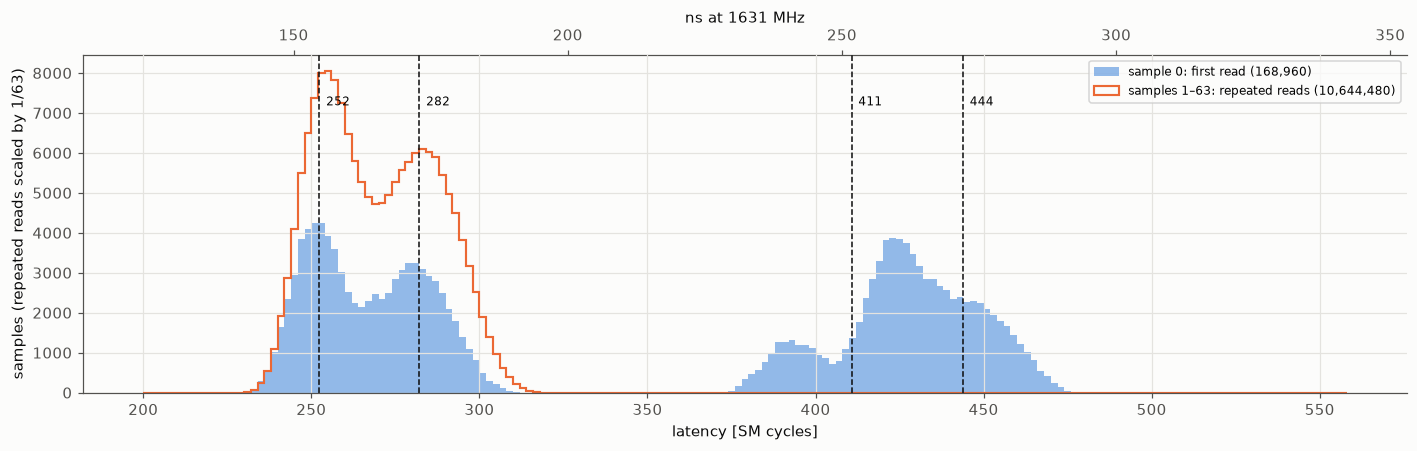

,centre,SD,CV %,share %
"near, own sub-node",252.4,7.7,3.1,26.7
"near, other sub-node",282.2,8.7,3.1,23.3
"far, low",410.7,13.8,3.4,24.9
"far, high",443.9,11.1,2.5,25.1


samples above 560 cycles (not drawn): first reads 0, repeated reads 0 of 10,644,480


In [5]:
first = (k5.first_cycles - TP).values
rep = (seq[:, 1:].ravel() - TP)
cen, lab, sd, wt = kmeans1d(*np.unique(first, return_counts=True), k=4)
fig, ax = plt.subplots(figsize=(13, 4.2))
bins = np.arange(200, 560, 2)
ax.hist(first, bins=bins, histtype="stepfilled", color=PAL[0], alpha=0.5, label=f"sample 0: first read ({len(first):,})")
ax.hist(rep, bins=bins, histtype="step", color=PAL[1], lw=1.4, label=f"samples 1–63: repeated reads ({len(rep):,})", weights=np.full(len(rep), 1 / 63))
for c in cen:
    ax.axvline(c, color=INK, ls="--", lw=1); ax.text(c + 2, ax.get_ylim()[1] * 0.85, f"{c:.0f}", fontsize=8)
ax.set_xlabel("latency [SM cycles]"); ax.set_ylabel("samples (repeated reads scaled by 1/63)"); ax.legend(fontsize=8)
sec = ax.secondary_xaxis("top", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_xlabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()
display(pd.DataFrame({"centre": cen, "SD": sd, "CV %": 100 * sd / cen, "share %": 100 * wt / wt.sum()},
                     index=["near, own sub-node", "near, other sub-node", "far, low", "far, high"]).round(1)
        .style.format("{:.1f}").set_caption("4-means classes of all first reads (timer pair removed)"))
print(f"samples above 560 cycles (not drawn): first reads {(first > 560).sum()}, repeated reads {(rep > 560).sum()} of {len(rep):,}")

In [6]:
quad, partner = quad_table(k5, sig, groups, TP)
tq = quad.groupby(["partition", "position"]).c.agg(median="median", p5=lambda x: x.quantile(.05), p95=lambda x: x.quantile(.95), mean="mean", n="size")
display(tq.round(1).style.format(precision=1).set_caption("first reads by placement of the line relative to the reading SM (cycles, timer pair removed)"))
names_ = {0: "S0 {G0,G6}", 1: "S1 {G4,G5}", 2: "S2 {G1,G2}", 3: "S3 {G3,G7}"}
names_ = {k: v for k, v in names_.items()}
sub_g = sig.groupby("subnode").gpc.agg(lambda x: "{" + ",".join(f"G{g}" for g in sorted(set(x))) + "}")
print("partner sub-nodes (the far sub-node each sub-node reads fastest): "
      + ", ".join(f"S{a} {sub_g[a]} → S{b} {sub_g[b]}" for a, b in sorted(partner.items())))
m = tq["mean"]
print(f"additive check: same/same {m.iloc[3]:.1f} + sub-node step {m.iloc[2]-m.iloc[3]:.1f} + partition step {m.iloc[1]-m.iloc[3]:.1f} "
      f"= {m.iloc[2]+m.iloc[1]-m.iloc[3]:.1f} vs measured other/other {m.iloc[0]:.1f} (means)")

partner sub-nodes (the far sub-node each sub-node reads fastest): S0 {G0,G6} → S3 {G3,G7}, S1 {G4,G5} → S2 {G1,G2}, S2 {G1,G2} → S1 {G4,G5}, S3 {G3,G7} → S0 {G0,G6}
additive check: same/same 251.6 + sub-node step 29.0 + partition step 161.5 = 442.2 vs measured other/other 441.8 (means)


**Figure 3 — all samples.**
- The first reads (blue) form four groups: near hits in the own and the other sub-node, and far hits in two groups.
- Reads 2–64 (orange) contain only the two near groups: after its first read, no line is ever far again.
- A small third far group near 390 cycles holds ≈ 12 % of the far first reads. It occurs only for lines in the partner sub-node (table below), for some lines and some SMs of a sub-node: a finer structure than sub-nodes, which this experiment does not resolve.

**The 2 × 2 structure (table above).**
- The far sub-node an SM reads fastest is always the same one: S0 ↔ S3 and S1 ↔ S2 are partners across the partition boundary.
- With that pairing, every first read falls into one of four cells. The two costs simply add (means): other sub-node position +29.0 cycles, other partition +161.5. Both together are predicted at 442.2 cycles and measured at 441.8.
- The L2 therefore behaves like a 2 × 2 grid of quadrants: {G0, G6} | {G3, G7} on one row and {G4, G5} | {G1, G2} on the other. Crossing between the partitions costs ≈ 162 cycles, crossing between the two rows ≈ 29.

In [7]:
agg = sig.groupby("gpc").agg(SMs=("smid", "size"), partition=("partition", lambda x: "/".join(map(str, sorted(set(x))))),
                             subnode=("subnode", lambda x: "/".join(map(str, sorted(set(x))))),
                             near=("near_median", "median"), near_own_subnode=("near_same_subnode_median", "median"),
                             near_other_subnode=("near_other_subnode_median", "median"), subnode_offset=("subnode_offset", "median"),
                             far=("far_median", "median"), far_low=("far_lo_median", "median"), far_high=("far_hi_median", "median"),
                             copy=("copy_median", "median"), home_repeat=("home_repeat_median", "median"))
agg = agg.loc[gpcs]
display(agg.rename(index=lambda g: f"G{g}").round(1).style.format(precision=1)
        .set_caption("per GPC: medians over its SMs of each SM's median (cycles, timer pair removed)"))
spread = sig.groupby("partition")[["near_median", "far_median", "near_same_subnode_median", "near_other_subnode_median", "copy_median"]].agg(["min", "max"])
display(spread.round(1).style.format(precision=1).set_caption("range of the per-SM medians within each partition"))
odd = sig[sig.smid >= 124].set_index("smid")[["gpc", "partition", "subnode", "near_same_subnode_median", "near_other_subnode_median", "far_median", "copy_median"]]
display(odd.round(1).style.format(precision=1).set_caption("SMs 124–131"))
for p in (0, 1):
    g = groups[p]
    other = groups[1 - p]["line"]
    fl, cl = g["far_line"], g["copy_line"]
    common = fl.index.intersection(other.index)
    a_far = (fl[common] == other[common]).mean(); a_copy = (cl[common] == other[common]).mean()
    print(f"partition {p}: first component explains {100*g['ev']:.0f} % of the centred near matrix "
          f"({100*g['far_ev']:.0f} % far, {100*g['copy_ev']:.0f} % repeated reads of far lines); "
          f"line groups of far first reads vs the lines' sub-node groups at home: {100*max(a_far, 1-a_far):.0f} % agree; "
          f"line groups of the copies vs home sub-node groups: {100*max(a_copy, 1-a_copy):.0f} % agree")

,SMs,partition,subnode,near,near_own_subnode,near_other_subnode,subnode_offset,far,far_low,far_high,copy,home_repeat
gpc,,,,,,,,,,,,
G0,12,0,0,258.5,252.0,282.5,30.5,428.5,420.0,446.5,280.0,258.0
G4,18,0,1,272.2,251.5,278.0,30.0,425.5,419.5,445.0,265.0,272.0
G5,18,0,1,273.5,252.5,279.5,30.0,425.5,419.5,445.0,266.0,273.0
G6,18,0,0,256.0,249.5,280.5,33.0,426.2,420.0,443.5,278.0,256.0
G1,16,1,2,262.5,254.0,282.0,28.0,433.5,419.5,448.0,282.0,260.5
G2,16,1,2,258.5,250.0,277.0,28.0,427.5,415.0,441.5,276.5,258.0
G3,16,1,3,272.5,252.5,281.0,29.0,426.0,422.0,443.5,264.0,273.8
G7,18,1,3,269.8,249.5,277.5,28.5,424.0,420.5,440.0,262.5,270.8


,gpc,partition,subnode,near_same_subnode_median,near_other_subnode_median,far_median,copy_median
smid,,,,,,,
124,0,0,0,244.0,270.0,416.0,266.0
125,0,0,0,245.0,270.0,418.0,266.0
126,4,0,1,248.0,283.0,426.0,264.0
127,4,0,1,249.0,283.0,425.0,264.0
128,5,0,1,249.0,284.0,428.0,264.0
129,5,0,1,249.0,284.0,427.0,264.0
130,0,0,0,250.0,286.0,430.0,284.0
131,0,0,0,250.0,285.0,430.0,284.0


partition 0: first component explains 95 % of the centred near matrix (95 % far, 96 % repeated reads of far lines); line groups of far first reads vs the lines' sub-node groups at home: 100 % agree; line groups of the copies vs home sub-node groups: 100 % agree
partition 1: first component explains 95 % of the centred near matrix (95 % far, 96 % repeated reads of far lines); line groups of far first reads vs the lines' sub-node groups at home: 100 % agree; line groups of the copies vs home sub-node groups: 100 % agree


- **Partitions and sub-nodes are properties of GPCs.** The per-GPC table shows one partition and one sub-node per GPC.
- **SMs 124–131 behave like the rest of their GPC.** These SMs (TPCs 62–65) never take part in larger clusters, but here they show the partition and sub-node of the GPC they belong to (G0, G4, G5) and normal latencies.
- **Copies stay in the line's sub-node position.** Reads 2–64 of far-homed lines ("copy") show the same two near groups as home reads, and the line grouping of the copies agrees 100 % with the line's sub-node group at home. Two consequences:
  - a copy goes to the partner sub-node of the line's home sub-node, i.e. the same row of the 2 × 2 grid. The SMs of that partner sub-node read the copy at ≈ 257 cycles, the others at ≈ 287;
  - every line has one row (S0/S3 or S1/S2), and that row holds both the line itself and every copy of it.
- **The far first read reflects the same row structure:** reaching the partner sub-node is ≈ 26–29 cycles cheaper than reaching the other far sub-node.

### 3. Which address bits choose the partition (K2)

**Figure 4 — which address bits move a line to the other partition.**
- For each bit b, 32 base lines L were compared with L ⊕ 2^b: share of the pairs whose homes differ, over both labelling directions and 3 repetitions (192 pairs per bit).
- Bits 7–20 lie inside a 2 MiB page: physical address bits. Higher bits go to another page of the allocation.

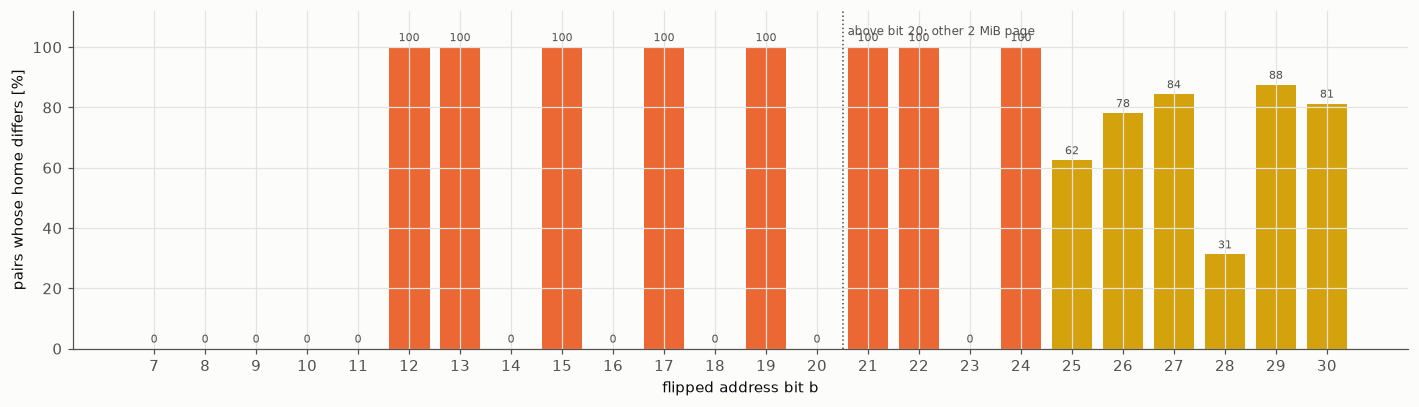

pairs per bit: 192 (32 bases × 2 directions × reps); per-direction share: max difference between the two directions 0.0 points
bits 7–20 that flip the home in every pair: [12, 13, 15, 17, 19]
XOR model of these bits: predicts 100.00 % of 17472 two-bit flips and 100.00 % of 6144 random multi-bit flips (bits 7–20)


In [8]:
hb = read_run("08__l2__hashbits.csv", RID["k2"])
frac, coef = k2_bits(hb)
lin = k2_linearity(hb, coef)
fr = hb[hb.set == "single"].groupby(["bit", "probe_smid"]).flipped_class_changed.mean().unstack()
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(7, 31)
cols = [PAL[1] if frac[b] >= 0.9 else (PAL[0] if frac[b] <= 0.1 else PAL[4]) for b in x]
ax.bar(x, 100 * frac.loc[x], color=cols)
for b in x:
    ax.text(b, 100 * frac[b] + 2, f"{100*frac[b]:.0f}", ha="center", fontsize=7.5, color=INK2)
ax.axvline(20.5, color=INK2, ls=":", lw=1); ax.text(20.6, 104, "above bit 20: other 2 MiB page", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xlabel("flipped address bit b"); ax.set_ylabel("pairs whose home differs [%]"); ax.set_ylim(0, 112)
fig.tight_layout(); plt.show()
print(f"pairs per bit: {int(hb[hb.set=='single'].groupby('bit').size().median())} (32 bases × 2 directions × reps); "
      f"per-direction share: max difference between the two directions {100*(fr.max(axis=1)-fr.min(axis=1)).max():.1f} points")
print("bits 7–20 that flip the home in every pair:", [b for b in range(7, 21) if coef.get(b) == 1])
print(f"XOR model of these bits: predicts {100*lin['pair'][0]:.2f} % of {lin['pair'][1]} two-bit flips and "
      f"{100*lin['mask'][0]:.2f} % of {lin['mask'][1]} random multi-bit flips (bits 7–20)")

In [9]:
# First reads of every K2 line (sample 0 rows only), home label per (rep, direction)
parts = []
for ch in pd.read_csv(f"{R}/08__l2__probe_k2.csv", chunksize=2_000_000,
                      usecols=["run_id", "probe_smid", "line_offset", "sample_idx", "cycles", "rep", "line_home"]):
    parts.append(ch[(ch.run_id == RID["k2"]) & (ch.sample_idx == 0)])
f0 = pd.concat(parts, ignore_index=True)
cons = f0.groupby("line_offset").line_home.agg(["mean", "size"])
print(f"{len(cons)} lines, {int(cons['size'].median())} first reads each; lines with the same home in every rep and direction: "
      f"{100*((cons['mean'] == 0) | (cons['mean'] == 1)).mean():.2f} %")
home = cons["mean"].round().astype(int)
PAGE = 2 << 20
M = sum(1 << b for b in range(7, 21) if coef.get(b) == 1)
par = lambda v: bin(int(v)).count("1") & 1
inpage = pd.Series(home.index % PAGE).value_counts()
scan = inpage[inpage >= 512].index  # the 4 fixed in-page offsets probed in every page
pg = pd.DataFrame({"off": home.index, "home": home.values})
pg = pg[(pg.off % PAGE).isin(scan)].assign(page=lambda d: d.off // PAGE)
pg["g"] = [h ^ par(o % PAGE & M) for h, o in zip(pg.home, pg.off)]
gp = pg.groupby("page").g.agg(["mean", "size"])
consistent = ((gp["mean"] == 0) | (gp["mean"] == 1)).mean()
G = gp["mean"].round().astype(int)
print(f"page term g(page) = home XOR parity(in-page bits {[b for b in range(7,21) if coef.get(b)==1]}): identical for all "
      f"{int(gp['size'].median())} probed offsets in {100*consistent:.1f} % of {len(gp)} pages; g = 1 in {100*G.mean():.1f} % of pages")
rows = []
npg = len(G)
for k in range(int(np.log2(npg))):
    pp = G.index.values
    q = pp ^ (1 << k)
    ok = np.isin(q, G.index.values)
    rows.append({"virtual address bit": 21 + k, "page pairs": int(ok.sum()),
                 "g differs [%]": 100 * (G.loc[pp[ok]].values != G.loc[q[ok]].values).mean()})
display(pd.DataFrame(rows).set_index("virtual address bit").round(1).T)

8823 lines, 6 first reads each; lines with the same home in every rep and direction: 100.00 %
page term g(page) = home XOR parity(in-page bits [12, 13, 15, 17, 19]): identical for all 4 probed offsets in 100.0 % of 1024 pages; g = 1 in 50.0 % of pages


virtual address bit,21,22,23,24,25,26,27,28,29,30
page pairs,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0
g differs [%],100.0,100.0,0.0,100.0,65.6,65.6,84.4,34.4,78.1,78.1


In [10]:
# Sub-node class of near first reads (the ~25-cycle split) versus address bits, from the same K2 data
nr = f0[f0.line_home == f0.probe_smid.map(part_of)].copy()
thr = {}
for (r_, p_), d in nr.groupby(["rep", "probe_smid"]):
    c_, l_, _, _ = kmeans1d(d.cycles.values, None, 2)
    thr[r_, p_] = (c_[0] + c_[1]) / 2
nr["slow"] = [c > thr[r_, p_] for c, r_, p_ in zip(nr.cycles, nr.rep, nr.probe_smid)]
cls = nr.groupby(["probe_smid", "line_offset"]).slow.mean().round()
s = hb[(hb.set == "single") & (hb.flipped_class_changed == 0)]
res = {}
for b in range(7, 31):
    x = s[s.bit == b]
    v = [(cls.get((p_, o1)), cls.get((p_, o2))) for p_, o1, o2 in zip(x.probe_smid, x.base_offset, x.flipped_offset)]
    v = [(a_, b_) for a_, b_ in v if a_ is not None and b_ is not None]
    if v:
        res[b] = 100 * np.mean([a_ != b_ for a_, b_ in v])
sub = pd.Series(res, name="near lines whose sub-node class differs after flipping bit b [%]")
display(sub.round(0).to_frame().T)

,7,8,9,10,11,14,16,18,20,23,25,26,27,28,29,30
near lines whose sub-node class differs after flipping bit b [%],0.0,28.0,0.0,66.0,75.0,81.0,69.0,44.0,28.0,53.0,58.0,29.0,60.0,59.0,25.0,67.0


- **Home labels are exact.** Every one of the 8823 lines got the same home in all 3 repetitions and in both directions, and the two directions are exactly complementary: 4384 lines are far for SM 2, the other 4439 for SM 0. The home of a line does not depend on who touched it, only on its address.
- **Inside a page, the partition is the parity of five bits: 12, 13, 15, 17 and 19.**
  - The lowest participating bit is 12, so a line's home is constant within 4 KiB and changes between the two halves of every 8 KiB.
  - Bits 7–11, 14, 16, 18 and 20 never change it.
  - The XOR (parity) model of these five bits predicts the home change of all 17 472 two-bit flips and all 6144 random multi-bit flips of bits 7–20.
- **Above the page.**
  - Every 2 MiB page carries one extra term g(page): the same for all four probed offsets in each of 1024 pages, and 1 in exactly half of them.
  - Flipping virtual-address bit 21, 22 or 24 always inverts g, bit 23 never does, and bits 25–30 do so for 31–88 % of the pairs.
  - So within this allocation the pages are physically contiguous in aligned 32 MiB groups, and physical bits 21, 22 and 24 belong to the hash; bit 23 does not.
  - The higher physical bits cannot be identified from user space: which physical page backs a virtual page is not visible.
  - In total at least eight bits take part: 12, 13, 15, 17, 19, 21, 22, 24.
- **The sub-node of a line is not such a parity.** No single bit of 7–30 switches the sub-node group (last table): flips change it for 25–81 % of lines, except bits 7 and 9, which never do. The choice of sub-node, unlike that of the partition, is a non-linear function of the address, presumably part of the slice selection.

### 4. Copies: who reads what, and what a write does (K3)

**Figure 5 — the life of a line in three SMs.**
- A writes 32 lines: 16 homed in A's partition (orange), 16 in B's (blue).
- Then, in order: B reads each line 64 times, C (B's partition, another GPC) does the same, then A; then A rewrites the lines and B reads them again.
- Median over lines and 5 repetitions, p5–p95 shaded; each phase is its own kernel launch. The three triples cross the partition boundary; the fourth triple (all three SMs in partition 0) is in the table only.

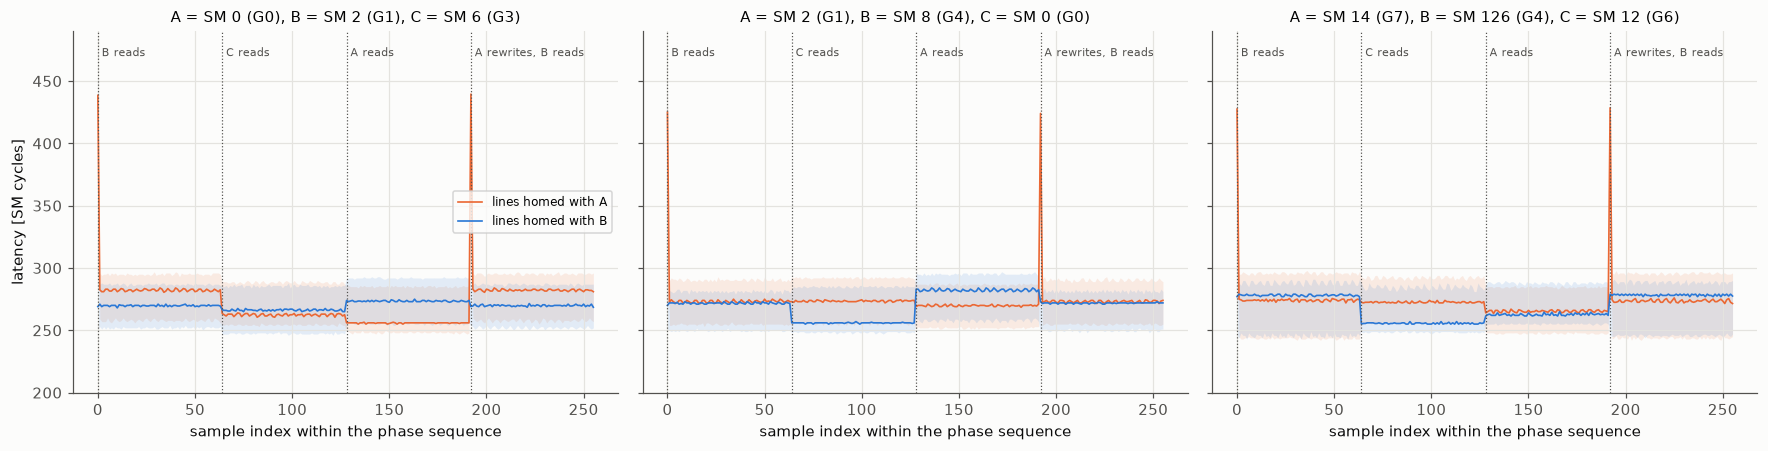

In [11]:
k3 = read_run("08__l2__probe.csv", RID["k3"])
k3 = k3[k3.kernel == "K3"].copy()
k3["cyc"] = k3.cycles - TP
repl = read_run("08__l2__replication.csv", RID["k3"])
trip = repl[["a_smid", "b_smid", "c_smid"]].drop_duplicates().values.tolist()
PH = ["b_read", "c_read", "a_read", "b_read_after_a_write"]
PHL = ["B reads", "C reads", "A reads", "A rewrites, B reads"]
PG = sig.groupby("gpc").partition.first()
apart = lambda a: int(PG[GPC[a]])
cross_t = [t for t in trip if apart(t[0]) != apart(t[1])]
same_t = [t for t in trip if apart(t[0]) == apart(t[1])]
fig, axs = plt.subplots(1, len(cross_t), figsize=(5.4 * len(cross_t), 4.2), sharey=True, squeeze=False)
for ax, (A, B, C) in zip(axs[0], cross_t):
    d = k3[(k3.first_touch_smid == A) & (k3.seq_mode == "launch") & (((k3.probe_smid == B) & k3.phase.isin(["b_read", "b_read_after_a_write"]))
                                                                   | ((k3.probe_smid == C) & (k3.phase == "c_read")) | ((k3.probe_smid == A) & (k3.phase == "a_read")))]
    d = d.assign(x=d.phase.map({p: i for i, p in enumerate(PH)}) * 64 + d.sample_idx,
                 hm=np.where(d.line_home == apart(A), "lines homed with A", "lines homed with B"))
    for c, h in zip([PAL[1], PAL[0]], ["lines homed with A", "lines homed with B"]):
        g = d[d.hm == h].groupby("x").cyc
        ax.plot(g.median().index, g.median(), "-", lw=1.1, color=c, label=h)
        ax.fill_between(g.median().index, g.quantile(.05), g.quantile(.95), color=c, alpha=0.12, lw=0)
    for i, l in enumerate(PHL):
        ax.axvline(64 * i, color=INK2, ls=":", lw=0.8); ax.text(64 * i + 2, 470, l, fontsize=7.5, color=INK2)
    ax.set_title(f"A = SM {A} (G{GPC[A]}), B = SM {B} (G{GPC[B]}), C = SM {C} (G{GPC[C]})", fontsize=9.5)
    ax.set_xlabel("sample index within the phase sequence"); ax.set_ylim(200, 490)
axs[0][0].set_ylabel("latency [SM cycles]"); axs[0][0].legend(fontsize=8, loc="center right")
fig.tight_layout(); plt.show()

In [12]:
r = repl.copy()
r["triple"] = [f"A {a} G{GPC[a]} · B {b} G{GPC[b]} · C {c} G{GPC[c]}" for a, b, c in zip(r.a_smid, r.b_smid, r.c_smid)]
r["home"] = np.where(r.line_home == r.a_smid.map(apart), "homed with A", "homed with B")
r["cyc"] = r.median_cycles - TP
PHS = ["b_first", "b_repeat", "c_first", "a_after_first", "b_after_a_write_first", "b_after_a_write_repeat"]
t = r[r.phase.isin(PHS)].pivot_table(index=["triple", "home"], columns=["phase"], values="cyc", aggfunc="median")[PHS]
display(t.round(0).style.format("{:.0f}").set_caption("per-line values (sample 0 = *_first, median of samples 1–63 = *_repeat), median over lines and reps, both sequencings; cycles"))
lf = r[r.phase.isin(PHS)].pivot_table(index=["seq_mode"], columns=["home", "phase"], values="cyc", aggfunc="median")
display(lf.round(0).style.format("{:.0f}").set_caption("launch-sequenced vs flag-sequenced (all triples)"))
ok = r[r.phase.str.startswith("b_after")].qword1_ok
print(f"B read the value A wrote last in {100*ok.mean():.1f} % of {len(ok)} line reads after the rewrite "
      f"(and the earlier token in {100*r[r.phase=='b_first'].qword1_ok.mean():.1f} % before it)")
fl = r[(r.seq_mode == "flag") & (r.phase == "b_after_a_write_first")]
gap = (fl.phase_t0_ns - r[(r.seq_mode == "flag") & (r.phase == "a_after_first")].phase_t1_ns.values[:len(fl)]) / 1e3
print(f"flag mode: B's last phase started {np.median(gap):.1f} µs (median) after A's read phase ended (A's rewrite in between)")

B read the value A wrote last in 100.0 % of 2560 line reads after the rewrite (and the earlier token in 100.0 % before it)
flag mode: B's last phase started 1.8 µs (median) after A's read phase ended (A's rewrite in between)


- **B's first read of A's lines is far (424–438 cycles), the next 63 are near (≈ 275):** B's read created a copy in B's partition.
- **C finds the copy.** C's first read of the same lines is near (263–273 cycles), although C never read them and sits in another GPC and another sub-node: **a copy serves the whole partition**, not just the SM that caused it.
- **A rewriting a line removes the copy.** After A's rewrite, B's first read is far again (424–438) and returns the new value in 100 % of 2560 line reads.
  - The write updates the line's home and invalidates the copy in the other partition. Stale data was never observed.
  - When the line is homed in B's partition, A's write goes there and B's reads stay near.
- **Launch boundaries change nothing.** The same sequence ordered by release/acquire flags inside one kernel launch gives the same values within 1–2 cycles (second table). The copies are not an artefact of kernel boundaries.
- **The control triple inside one partition never sees a far access.**

### 5. How much one SM can keep (K4)

**Figure 6 — one SM chasing a growing footprint.** A random chain over all lines of the footprint, after the L2 was emptied and the lines written either by the probe SM or alternately by SM 0 and SM 2.
- (a): latency per hop for the first and the third timed pass, and for an untimed fourth pass (whole-pass time / hops); median over SMs 0 and 2 and 3 repetitions.
- (b), (c): every timed access sorted into four classes (near hit, far hit, HBM miss of the near and of the far class). The class centres come from the K5 near and far medians and a 2-means of the misses at ≥ 64 MiB; the boundaries are the midpoints.

class centres (near and far hit: K5 medians; HBM: 2-means of the misses at ≥ 64 MiB), cycles: near hit 265, far hit 427, HBM, near class 507, HBM, far class / slower 691; boundaries 346, 467, 599


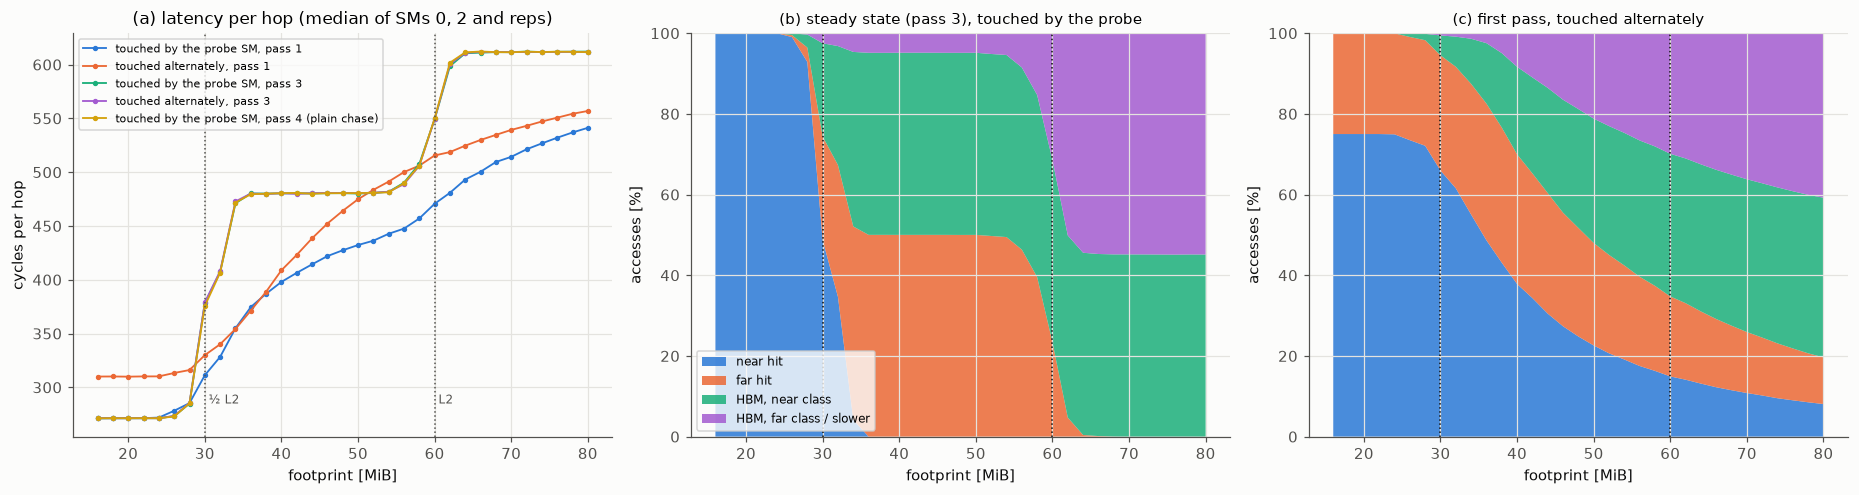

In [13]:
cap = read_run("08__l2__capacity.csv", RID["k4"])
ch = read_run("08__l2__capacity_hist.csv", RID["k4"])
ch["cyc"] = ch.cycles - TP
hb_ = ch[(ch.footprint_bytes >= 64 << 20) & (ch["pass"] == 2) & (ch.cyc > 470) & (ch.cyc < 1000)].groupby("cyc")["count"].sum()
cm, _, _, _ = kmeans1d(hb_.index.values, hb_.values, 2)
cen4 = np.array([sig.near_median.median(), sig.far_median.median(), cm[0], cm[1]])
edges = [(cen4[i] + cen4[i + 1]) / 2 for i in range(3)]
names = ["near hit", "far hit", "HBM, near class", "HBM, far class / slower"]
ch["cls"] = np.searchsorted(edges, ch.cyc.values)
fr = ch.groupby(["touch_pattern", "footprint_bytes", "pass", "cls"])["count"].sum().unstack(fill_value=0)
fr = fr.div(fr.sum(axis=1), axis=0)
print("class centres (near and far hit: K5 medians; HBM: 2-means of the misses at ≥ 64 MiB), cycles: " + ", ".join(f"{n} {c:.0f}" for n, c in zip(names, cen4))
      + "; boundaries " + ", ".join(f"{e:.0f}" for e in edges))
cur = cap.groupby(["touch_pattern", "pass", "footprint_bytes"]).cycles_per_hop.median()
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axs[0]
for c, (pat, ps, lab) in zip(PAL, [("probe", 0, "touched by the probe SM, pass 1"), ("alternate", 0, "touched alternately, pass 1"),
                                   ("probe", 2, "touched by the probe SM, pass 3"), ("alternate", 2, "touched alternately, pass 3"),
                                   ("probe", 3, "touched by the probe SM, pass 4 (plain chase)")]):
    y = cur[pat, ps]
    ax.plot(y.index / 2**20, y.values, "-o", ms=2.5, lw=1.2, color=c, label=lab)
for xv, l in [(30, "½ L2"), (60, "L2")]:
    ax.axvline(xv, color=INK2, ls=":", lw=1); ax.text(xv + 0.5, 285, l, fontsize=8, color=INK2)
ax.set_xlabel("footprint [MiB]"); ax.set_ylabel("cycles per hop"); ax.legend(fontsize=7.5); ax.set_title("(a) latency per hop (median of SMs 0, 2 and reps)")
for ax, (pat, ps, tt) in zip(axs[1:], [("probe", 2, "(b) steady state (pass 3), touched by the probe"), ("alternate", 0, "(c) first pass, touched alternately")]):
    d = fr.loc[(pat, slice(None), ps)].droplevel([0, 1]) if False else fr.xs((pat, ps), level=("touch_pattern", "pass"))
    ax.stackplot(d.index / 2**20, *[100 * d.get(k, 0) for k in range(4)], labels=names, colors=[PAL[0], PAL[1], PAL[2], PAL[3]], alpha=0.85)
    for xv in (30, 60):
        ax.axvline(xv, color=INK, ls=":", lw=1)
    ax.set_xlabel("footprint [MiB]"); ax.set_ylabel("accesses [%]"); ax.set_ylim(0, 100); ax.set_title(tt, fontsize=10)
axs[1].legend(fontsize=8, loc="lower left")
fig.tight_layout(); plt.show()

In [14]:
tab = fr.xs(2, level="pass").unstack("touch_pattern")
sel = [F for F in sorted(cap.footprint_bytes.unique()) if (F >> 20) % 8 == 0 or (F >> 20) in (26, 30, 34, 38)]
show = pd.DataFrame({f"{names[k]} [%], {pat}": 100 * tab[(k, pat)] for k in range(4) for pat in ("probe", "alternate") if (k, pat) in tab})
show.index = show.index // 2**20
display(show.loc[[F >> 20 for F in sel]].round(1).style.format("{:.1f}").set_caption("steady state (pass 3): access classes vs footprint [MiB]"))
nc = NCU["capacity"].copy()
nc["MiB"] = nc.lines.astype(float) * 128 / 2**20
hops = nc.lines.astype(float)
nt = pd.DataFrame({"footprint MiB": nc.MiB, "SM": nc.probe_smid, "touch": nc.what, "cycles/hop": nc.first_median,
                   "L2 lookup hits / hop": nc["lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum"] / hops,
                   "L2 lookup misses / hop": nc["lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum"] / hops,
                   "partition-link sectors / hop": nc["lts__t_sectors_srcunit_ltcfabric.sum"] / hops,
                   "HBM bytes / hop": nc["dram__bytes_read.sum"] / hops})
display(nt[nt.SM == 0].set_index(["footprint MiB", "touch"]).drop(columns="SM").round(2).style.format(precision=2)
        .set_caption("profiled plain chase of SM 0 after two warm passes"))

,"near hit [%], probe","near hit [%], alternate","far hit [%], probe","far hit [%], alternate","HBM, near class [%], probe","HBM, near class [%], alternate","HBM, far class / slower [%], probe","HBM, far class / slower [%], alternate"
footprint_bytes,,,,,,,,
16,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
24,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
26,99.0,98.9,0.5,0.6,0.4,0.5,0.1,0.1
30,48.7,48.6,25.6,25.7,23.1,23.2,2.5,2.5
32,34.6,33.0,32.7,33.5,29.5,30.2,3.2,3.2
34,4.1,3.8,47.9,48.1,43.3,43.4,4.6,4.7
38,0.0,0.0,50.0,50.0,45.1,45.1,4.9,4.9
40,0.0,0.0,50.0,50.0,45.1,45.1,4.9,4.8
48,0.0,0.0,50.0,50.0,45.1,45.1,4.9,4.9


**What one SM can keep in L2 (steady state, panel b and the first table).**

| footprint | what the chase sees |
|---|---|
| ≤ 26 MiB | 100 % near hits, 271 cycles per hop |
| 30–34 MiB | near hits disappear quickly |
| 38–52 MiB | exactly **50 % far hits** and ≈ 45 % HBM misses of the near class (+5 % far class), ≈ 480 cycles per hop |
| ≥ 64 MiB | no hits: 45 % HBM near class (≈ 507 cycles), 55 % far class (≈ 691); 612 cycles per hop |

**Interpretation.**
- **Up to ≈ 26–30 MiB: everything fits in the reader's partition.** Every line the SM reads ends up in its own partition, at home or as a copy, and one partition holds 30 MiB.
- **Between 30 and 60 MiB: the far half still hits at home.** The reader's partition must hold its own half of the lines plus copies of the other half, more than it can hold, so a cyclic chase misses there every time. The half homed in the other partition still fits there: reads of those lines are far hits. The lines homed in the reader's own partition go to HBM.
- **Beyond ≈ 60 MiB:** the far half no longer fits at home either, and everything comes from HBM.

**Other observations.**
- **The touch pattern matters only for the first pass.** Lines written alternately by SMs of both partitions leave a quarter of the first reads far even at 16 MiB. From the second pass on, both patterns are identical.
- **The counters agree.** Below 24 MiB there is one L2 hit per hop. At 36–48 MiB there are 2 lookup misses (one 64-byte request to the reader's partition) and exactly 1 partition-link sector per hop, with ≈ 34 B of HBM reads per hop: half the hops miss to HBM. From 64 MiB every hop reads 64 B from HBM.

### 6. Hardware counters

Nsight Compute, application replay (each counter pass re-runs the binary with the full protocol), clock lock kept:
1. one line read 64 times per profiled kernel, 32 lines, from SM 2 and from SM 0 (lines written by SM 0);
2. L1 hits of 32 lines × 64 reads with `.cg` and `.ca`;
3. SM 2 reading 65 533 lines that SM 0 wrote: first reads of far-homed lines, first reads of near-homed lines, and a second read of the far-homed lines, plus an empty kernel as the profiler's own baseline.

In [15]:
nl = NCU["lines"].copy()
one = nl[nl.what == "line"].copy()
one["class"] = np.where(one.first_median.astype(float) - TP > 350, "far first read", "near first read")
cols = {"lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum": "lookup hits", "lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum": "lookup misses",
        "lts__t_sectors_srcunit_tex_op_read_lookup_hit.max": "hits in the busiest slice", "lts__t_sectors_srcunit_tex_op_read_lookup_miss.max": "misses in the busiest slice",
        "lts__t_sectors_srcunit_ltcfabric.sum": "partition-link sectors", "l1tex__t_sectors_pipe_lsu_mem_global_op_ld_lookup_hit.sum": "L1 hits"}
cols = {k: v for k, v in cols.items() if k in one}
display(one.groupby(["probe_smid", "class"])[list(cols)].median().rename(columns=cols).round(1)
        .assign(lines=one.groupby(["probe_smid", "class"]).size()).style.format(precision=1)
        .set_caption("one line, 64 reads (+1 TLB-warm read, 2 list reads), per profiled kernel: median over lines"))
l1 = nl[nl.what.str.startswith("l1_")].set_index("what")
print("32 lines × 64 reads from SM 0: L1 hits " + ", ".join(f"{w}: {int(l1.loc[w, 'l1tex__t_sectors_pipe_lsu_mem_global_op_ld_lookup_hit.sum'])}" for w in l1.index)
      + f" of {int(l1['l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum'].iloc[0])} global-load sectors")
for t in ("lines", "fabric", "capacity"):
    x = NCU[t][NCU[t].first_median.astype(float) > 0]
    print(f"ncu {t}: {int(x.pass_runs.iloc[0])} binary runs; profiled-kernel cycles in the first run / median of the others: "
          f"{(x.first_median_pass1.astype(float) / x.first_median.astype(float)).median():.2f}×")
print(f"L2 slices reported by the profiler: {int(nl['device__attribute_l2s_count'].iloc[0])}; counter passes per profiled kernel: "
      f"{int(nl['profiler__replayer_passes'].iloc[0])}")
fb = NCU["fabric"].set_index("what")
base = fb.loc["empty", "lts__t_sectors_srcunit_ltcfabric.sum"]
ft = pd.DataFrame({"lines": fb.lines, "partition-link sectors": fb["lts__t_sectors_srcunit_ltcfabric.sum"],
                   "minus empty kernel": fb["lts__t_sectors_srcunit_ltcfabric.sum"] - base,
                   "L2 lookup hits": fb["lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum"], "L2 lookup misses": fb["lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum"],
                   "median first read [cycles]": fb.first_median.astype(float) - TP})
display(ft.round(0).style.format(precision=0).set_caption("SM 2 reads 65 k lines touched by SM 0 (one read per line)"))
d_ = ft.loc["far_first", "partition-link sectors"] - ft.loc["near_first", "partition-link sectors"]
print(f"far first read − near first read: {d_:.0f} partition-link sectors = {d_ / ft.loc['far_first', 'lines']:.2f} per line")

32 lines × 64 reads from SM 0: L1 hits l1_cg: 48, l1_ca: 2064 of 2144 global-load sectors
ncu lines: 4 binary runs; profiled-kernel cycles in the first run / median of the others: 2.59×
ncu fabric: 4 binary runs; profiled-kernel cycles in the first run / median of the others: 2.60×
ncu capacity: 4 binary runs; profiled-kernel cycles in the first run / median of the others: 2.76×
L2 slices reported by the profiler: 96; counter passes per profiled kernel: 4


,lines,partition-link sectors,minus empty kernel,L2 lookup hits,L2 lookup misses,median first read [cycles]
what,,,,,,
empty,0,1330,0,0,0,-3
far_first,65533,151885,150555,82000,163850,428
near_first,65531,20610,19280,146679,32920,270
far_second,65533,4254,2924,161417,6,276


far first read − near first read: 131275 partition-link sectors = 2.00 per line


- **A far first read moves 64 bytes over the partition link.** Far first reads cost 2.00 link sectors more per line than near first reads. A second read of the same far-homed lines moves almost nothing: the copy serves it.
- **Each line is served by one slice.**
  - The profiler reports 96 L2 slices.
  - Its CSV export contains no per-slice values for these counters on this toolkit, so the slice that serves a given line cannot be identified here.
  - The `.max` roll-up shows that all 63–64 repeated reads of a line hit a single slice, and that the 2 miss sectors of a far first read fall into a single slice of the reader's partition.
- **`.cg` loads never hit in L1.** The 48 L1 hits come from reading the line list; `.ca` adds exactly 32 × 63 = 2016 L1 hits.
- **Anomaly: the first counter pass runs slow.** In all three profiles the first of the four counter passes ran the profiled kernels 2.6–2.8× slower than the other three. Reduced metric sets, profiled separately, run at normal speed and give the same counts within a few percent. Cycle counts in the tables above are therefore taken from passes 2–4, and counts are used as exported.

## Insights

**1. Placement in the L2 is a 2 × 2 grid, and the costs add up.** SM cycles at the locked 1635 MHz, timer pair removed, first reads of lines that exist only at home:

| line relative to the reading SM | median | p5–p95 |
|---|---|---|
| same partition, same sub-node | **251** (154 ns) | 240–265 |
| same partition, other sub-node | **280** (172 ns) | 265–297 |
| other partition, partner sub-node | **417** (256 ns) | 385–435 |
| other partition, other sub-node | **443** (272 ns) | 418–464 |

- Partition 0 = {G0, G4, G5, G6}, partition 1 = {G1, G2, G3, G7}.
- Sub-nodes {G0, G6}, {G4, G5} | {G1, G2}, {G3, G7}; partners {G0, G6} ↔ {G3, G7} and {G4, G5} ↔ {G1, G2}.
- Crossing the partition boundary costs **+162 cycles** and crossing between the two sub-node rows **+29**, independently of each other.
- On top of this, every SM has its own offset (−8 to +10 cycles around its GPC's median), shared by the two SMs of a TPC and the same for every line. It is a position term on the SM side.
- Labels for all 132 SMs are in the experiment's per-SM map.

**2. Homes are fixed by the address, and copies make far hits rare.**
- The partition is the parity of physical address bits 12, 13, 15, 17, 19, 21, 22, 24 and possibly further bits above 24. Lines alternate between the partitions every 4 KiB, and any buffer is split exactly in half.
- Which SM touches a line first does not move its home.
- Any read or write of a line leaves a copy in the accessor's partition, and that copy:
  - serves every SM of the partition;
  - sits in the same sub-node row as the line's home;
  - is invalidated when the line is written from the other side, so readers never see stale data.
- Consequently, an SM pays the far latency at most once per line and partition, unless a write from the other partition intervenes. Data shared by both halves of the chip is held twice.

**3. Effective capacity for one reader is 30 MiB at near latency, and 60 MiB in total.**
- A single SM keeps everything at near latency only up to the size of one partition (≈ 30 MiB; the chase stays flat to 26 MiB).
- Between 30 and 60 MiB, half of its accesses become far hits served by the other partition, and the other half miss to HBM, even though the data would fit in the L2 once.
- Data placed so that it is read only from its home partition keeps the full 60 MiB at near latency.

**4. The partition link carries 64 B per far first read.** Repeated reads add no link traffic. The cost of sharing data across partitions is paid on first use and on every write.

**Limitations.**
- Address bits above 20 can be observed only through how the driver mapped the allocation. Here pages were contiguous in 32 MiB groups; other allocations may reveal more bits or fewer.
- The sub-node choice of a line is not a parity of address bits, and per-slice counter values are not exported by the profiler on this toolkit. The slice-level mapping remains open, together with the ≈ 390-cycle far mode and the per-SM position term.
- All latencies are for one thread on an otherwise idle GPU.